In [1]:
import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path
import h5py

from pyoculus.fields.slab_bfield_two_pert import SlabBfieldTwoPert
from pyoculus.maps import ToroidalBfieldSection
from pyoculus.solvers import PoincarePlot

In [5]:
results_dir = Path("num_results_loc/computed_manifolds")
poincare_dir = Path("num_results_loc/poincare_plots")

configs = list(range(11, 20)) + list(range(110, 122)) + [21, 22, 23]

manifolds = {}
parameters = {}
poincare_plots = {}

for config_id in configs:
    # Load manifolds
    path = results_dir / f"manifolds_{config_id}.npz"
    with np.load(path) as data:
        manifolds[config_id] = {
            key: data[key].copy()
            for key in data.files
        }

    # Load parameters
    path_json = results_dir / f"parameters_{config_id}.json"
    with open(path_json, "r", encoding="utf-8") as f:
        parameters[config_id] = json.load(f)

    # Load Poincare trajectories
    path_poincare = poincare_dir / f"pplot_{config_id}.npz"
    with np.load(path_poincare) as data:
        poincare_plots[config_id] = data["hits"].copy()

In [6]:
temperature_dir = Path("num_results_loc/FaADE")

def plot_temperature(
    ax,
    params,
    t_f=0.01,
    k_values=(4.0, 6.0, 8.0, 10.0, 12.0),
    nx=201,
    colors=("red", "orange", "green", "purple", "blue")
):
    """
    Plot temperature profiles on a secondary y-axis.

    Parameters
    ----------
    ax : matplotlib.axes.Axes
        Main axis containing Poincare plot and manifolds.
    params : dict
        Configuration parameters.
    t_f : float
        Final simulation time.
    k_values : iterable
        Exponents defining kappa_perp/kappa_parallel = 10^(-k).
    nx : int
        Spatial resolution.
    """

    ax_T = ax.twinx()

    delta1 = params["delta1"]
    delta2 = params["delta2"]
    iota = params["iota_prime"]

    for exp_k, color in zip(k_values, colors):

        filename = (
            f"2I_k{float(exp_k)}_tf{t_f}_"
            f"d{delta1}_{delta2}_res{nx}_"
            f"m1_dT_iota{float(iota)}_Neumann.jld2"
        )

        path = temperature_dir / filename

        if not path.exists():
            print(f"Temperature file not found: {filename}")
            continue

        with h5py.File(path, "r") as f:
            x_mid = np.asarray(f["x_mid"]).squeeze()
            u_mid = np.asarray(f["u_mid"]).squeeze()

        ax_T.plot(
            x_mid,
            u_mid,
            color=color,
            linewidth=2,
            label=rf"$\kappa_\perp/\kappa_\parallel = 10^{{-{int(exp_k)}}}$",
            zorder=4
        )

    ax_T.set_ylabel(r"$T(x)$")
    ax_T.set_xlim(0, 2)

    ax_T.legend(
        loc="lower right",
        title="Parallel transport",
        fontsize=9,
        title_fontsize=10,
        frameon=True
    )

    return ax_T

In [9]:
def plot_configuration(
    config_id,
    markersize=3,
    poincare=True,
    unwrapped=False,
    maxs=None,
    maxu=None,
    temperature=False,
    t_f=0.01,
    k_values=(4.0, 6.0, 8.0, 10.0, 12.0)
):

    params = parameters[config_id]
    data = manifolds[config_id]

    fig, ax = plt.subplots(figsize=(8, 6))

    # --------------------------------------------------
    # 1. Poincare plot
    # --------------------------------------------------

    if poincare:
        if config_id not in poincare_plots:
            raise ValueError(
                f"Poincare plot for configuration {config_id} "
                "has not been loaded."
            )

        hits = poincare_plots[config_id]

        for traj in hits:
            ax.scatter(
                traj[:, 0],
                traj[:, 1],
                color="black",
                marker=".",
                s=0.5,
                lw=0,
                alpha=0.35,
                zorder=1
            )

        ax.set_xlim(0, 2)

    # --------------------------------------------------
    # 2. Stable and unstable manifolds
    # --------------------------------------------------

    indices = sorted(
        int(key[len("stable"):])
        for key in data
        if key.startswith("stable")
        and key[len("stable"):].isdigit()
    )

    if maxs is None:
        maxs = [None] * len(indices)

    if maxu is None:
        maxu = [None] * len(indices)

    if len(maxs) != len(indices) or len(maxu) != len(indices):
        raise ValueError(
            f"Configuration {config_id} has {len(indices)} manifolds. "
            "maxs and maxu must have one entry per manifold."
        )

    first_plotted = True

    for j, i in enumerate(indices):

        stable_key = f"stable{i}"
        unstable_key = f"unstable{i}"

        if unwrapped:
            if f"stable_unwrapped{i}" in data:
                stable_key = f"stable_unwrapped{i}"

            if f"unstable_unwrapped{i}" in data:
                unstable_key = f"unstable_unwrapped{i}"

        if stable_key not in data or unstable_key not in data:
            continue

        stable = data[stable_key]
        unstable = data[unstable_key]

        ax.plot(
            stable[:maxs[j], 0],
            stable[:maxs[j], 1],
            color="cyan",
            marker=".",
            markersize=markersize,
            linestyle="",
            label="Stable" if first_plotted else None,
            zorder=2
        )

        ax.plot(
            unstable[:maxu[j], 0],
            unstable[:maxu[j], 1],
            color="magenta",
            marker=".",
            markersize=markersize,
            linestyle="",
            label="Unstable" if first_plotted else None,
            zorder=2
        )

        first_plotted = False

    # --------------------------------------------------
    # 3. Temperature profiles
    # --------------------------------------------------

    if temperature:
        ax_T = plot_temperature(
            ax,
            params,
            t_f=t_f,
            k_values=k_values
        )

    # --------------------------------------------------
    # 4. Figure formatting
    # --------------------------------------------------

    ax.set_title(
        rf"$m_1={params['m1']},\ n_1={params['n1']},\ "
        rf"\delta_1={params['delta1']},\ "
        rf"m_2={params['m2']},\ n_2={params['n2']},\ "
        rf"\delta_2={params['delta2']},\ "
        rf"\iota'={params['iota_prime']}$"
    )

    ax.set_xlim(0, 2)
    ax.set_ylim(0, 2*np.pi)

    ax.set_xlabel("x")
    ax.set_ylabel(r"$\theta$")

    return fig, ax

Temperature file not found: 2I_k4.0_tf0.01_d0.05_0.05_res201_m1_dT_iota2.0_Neumann.jld2
Temperature file not found: 2I_k6.0_tf0.01_d0.05_0.05_res201_m1_dT_iota2.0_Neumann.jld2
Temperature file not found: 2I_k8.0_tf0.01_d0.05_0.05_res201_m1_dT_iota2.0_Neumann.jld2
Temperature file not found: 2I_k10.0_tf0.01_d0.05_0.05_res201_m1_dT_iota2.0_Neumann.jld2
Temperature file not found: 2I_k12.0_tf0.01_d0.05_0.05_res201_m1_dT_iota2.0_Neumann.jld2


C:\Users\mirei\AppData\Local\Temp\ipykernel_21468\382293941.py:64: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_T.legend(


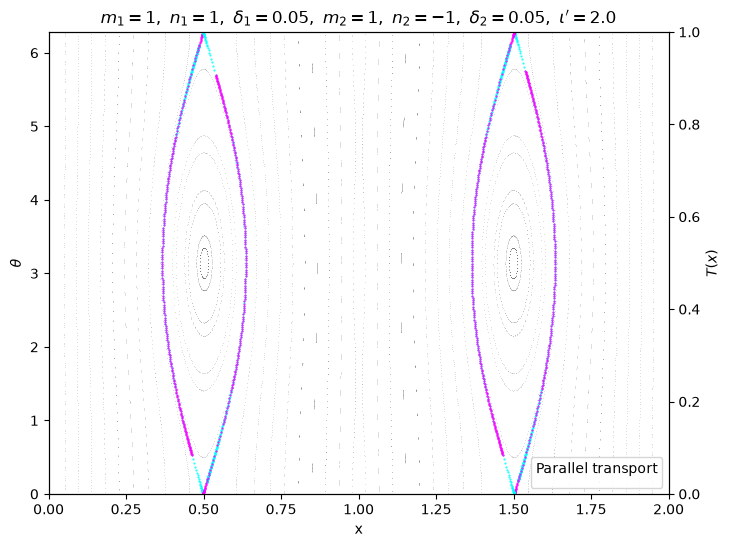

In [11]:
config_id = 11
fig, ax = plot_configuration(
    config_id,
    markersize=1,
    poincare=True,
    unwrapped=True,
    temperature=True,
    t_f=0.01,
    k_values=[4.0, 6.0, 8.0, 10.0, 12.0]
)
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

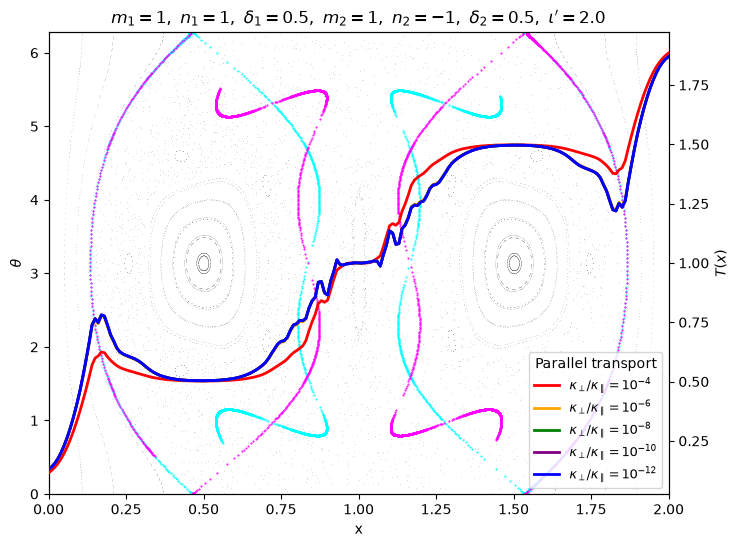

In [10]:
config_id = 12
fig, ax = plot_configuration(
    config_id,
    markersize=1,
    poincare=True,
    unwrapped=True,
    maxs=[1350, 700, 700, 1650], maxu=[2100, 700, 800, 1650],
    temperature=True,
    t_f=0.01,
    k_values=[4.0, 6.0, 8.0, 10.0, 12.0]
)

plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

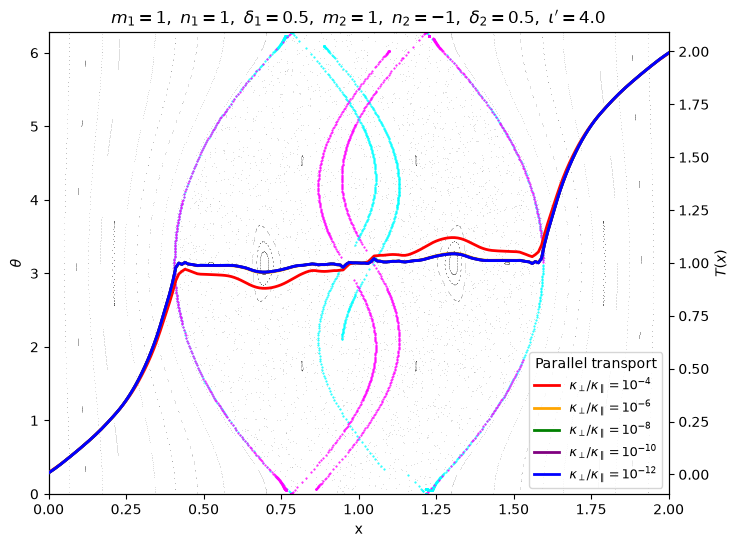

In [12]:
config_id = 13
fig, ax = plot_configuration(
    config_id,
    markersize=1,
    poincare=True,
    unwrapped=True,
    maxs=[1500, 300, 1000, 260], maxu=[300, 350, 400, 350],
    temperature=True,
    t_f=0.01,
    k_values=[4.0, 6.0, 8.0, 10.0, 12.0]
)
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

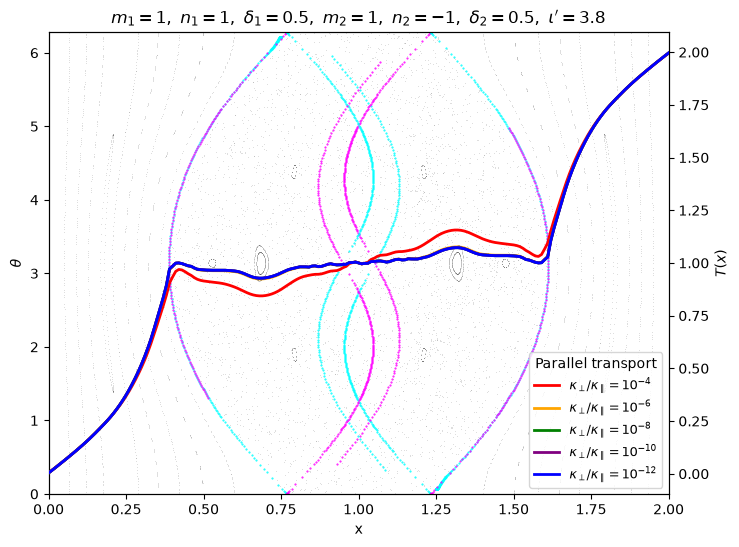

In [13]:
config_id = 14
fig, ax = plot_configuration(
    config_id,
    markersize=1,
    poincare=True,
    unwrapped=True,
     maxs=[260, 500, 500, 260], maxu=[265, None, None, 265],
    temperature=True,
    t_f=0.01,
    k_values=[4.0, 6.0, 8.0, 10.0, 12.0]
)
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

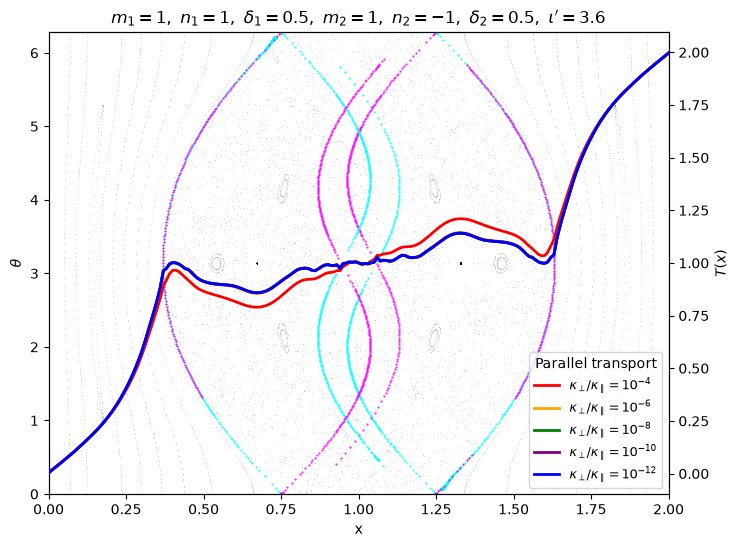

In [14]:
config_id = 15
fig, ax = plot_configuration(
    config_id,
    markersize=1,
    poincare=True,
    unwrapped=True,
    maxs=[260,500,500,340], maxu=[260,500,500,340],
    temperature=True,
    t_f=0.01,
    k_values=[4.0, 6.0, 8.0, 10.0, 12.0]
)
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

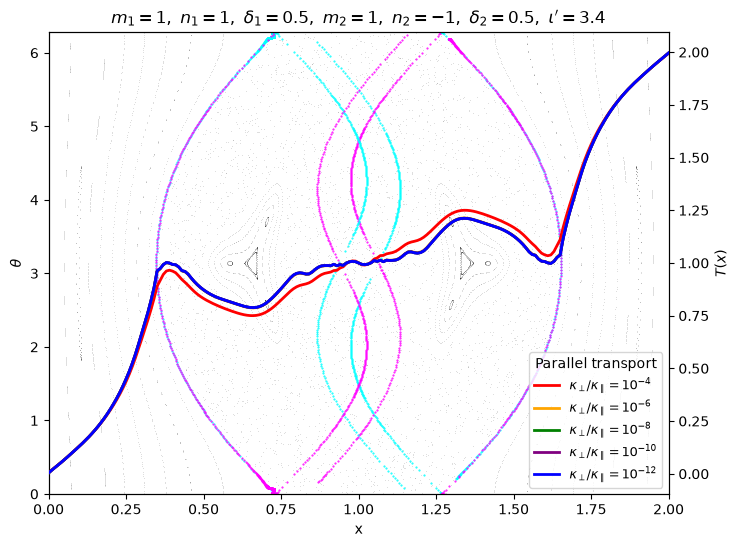

In [15]:
config_id = 16
fig, ax = plot_configuration(
    config_id,
    markersize=1,
    poincare=True,
    unwrapped=True,
    maxs=[335,4500,None,288], maxu=[305,380,None,295],
    temperature=True,
    t_f=0.01,
    k_values=[4.0, 6.0, 8.0, 10.0, 12.0]
)
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

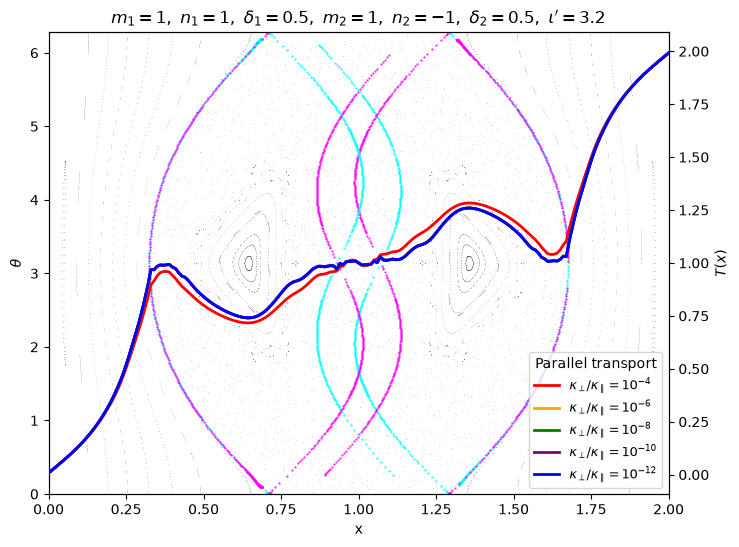

In [16]:
config_id = 17
fig, ax = plot_configuration(
    config_id,
    markersize=1,
    poincare=True,
    unwrapped=True,
    maxs=[350,300,None,337], maxu=[360,None,None,350],
    temperature=True,
    t_f=0.01,
    k_values=[4.0, 6.0, 8.0, 10.0, 12.0]
)
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

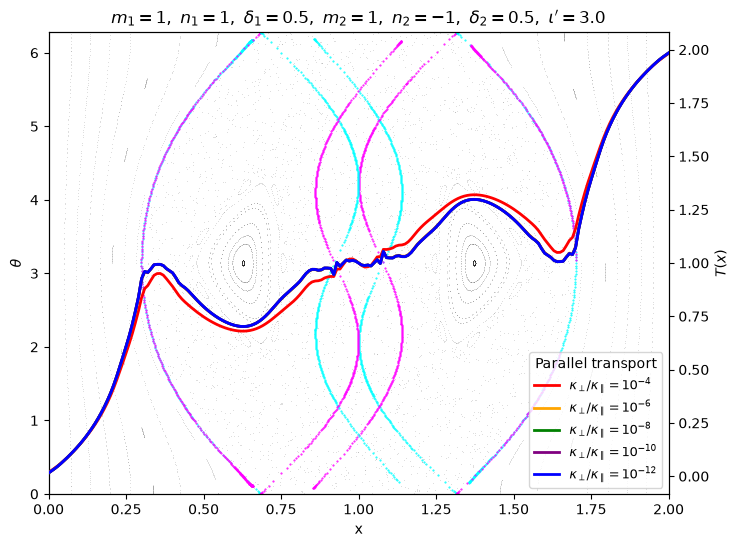

In [17]:
config_id = 18
fig, ax = plot_configuration(
    config_id,
    markersize=1,
    poincare=True,
    unwrapped=True,
    maxs=[370,300,None,355], maxu=[380,None,None,380],
    temperature=True,
    t_f=0.01,
    k_values=[4.0, 6.0, 8.0, 10.0, 12.0]
)
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

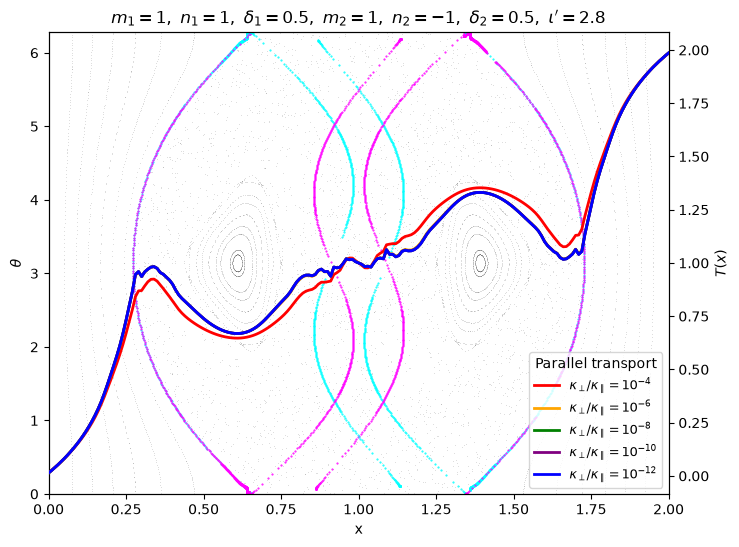

In [18]:
config_id = 19
fig, ax = plot_configuration(
    config_id,
    markersize=1,
    poincare=True,
    unwrapped=True,
    maxs=[370,None,None,400], maxu=[400,None,None,400],
    temperature=True,
    t_f=0.01,
    k_values=[4.0, 6.0, 8.0, 10.0, 12.0]
)
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

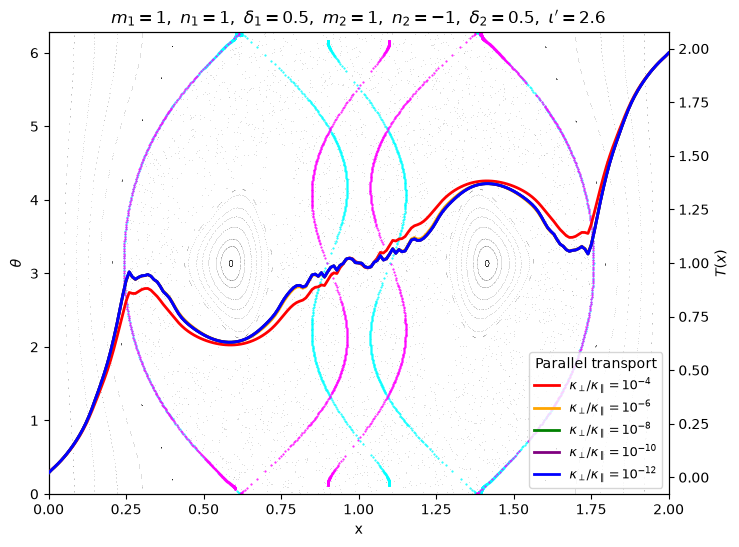

In [19]:
config_id = 110
fig, ax = plot_configuration(
    config_id,
    markersize=1,
    poincare=True,
    unwrapped=True,
    maxs=[500,None,None,500], maxu=[500,None,None,500],
    temperature=True,
    t_f=0.01,
    k_values=[4.0, 6.0, 8.0, 10.0, 12.0]
)

plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

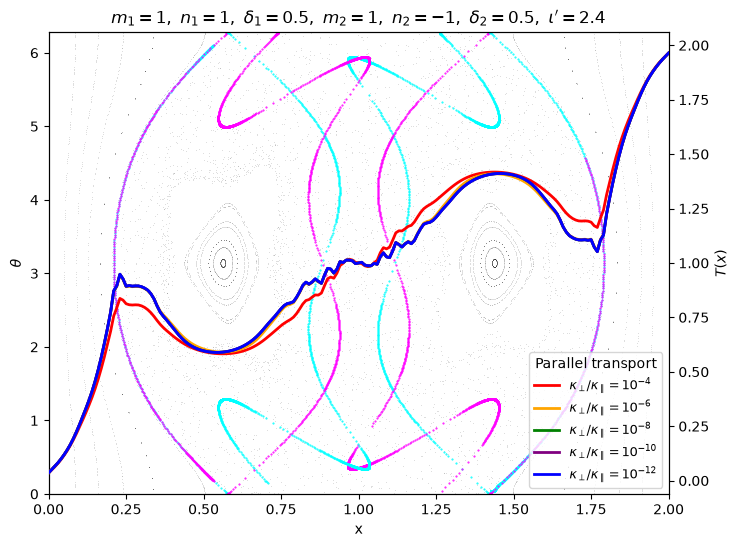

In [20]:
config_id = 111
fig, ax = plot_configuration(
    config_id,
    markersize=1,
    poincare=True,
    unwrapped=True,
    maxs=[1550,None,None,1600], maxu=[2100,None,None,1640],
    temperature=True,
    t_f=0.01,
    k_values=[4.0, 6.0, 8.0, 10.0, 12.0]
)
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

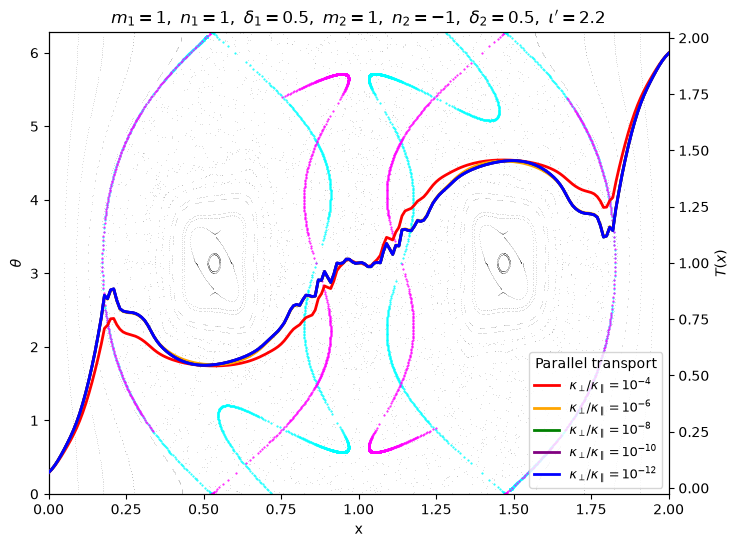

In [21]:
config_id = 112
fig, ax = plot_configuration(
    config_id,
    markersize=1,
    poincare=True,
    unwrapped=True,
    maxs=[1800,None,None,1800], maxu=[None,None,None,None],
    temperature=True,
    t_f=0.01,
    k_values=[4.0, 6.0, 8.0, 10.0, 12.0]
)
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

Temperature file not found: 2I_k4.0_tf0.01_d0.05_0.05_res201_m1_dT_iota2.0_Neumann.jld2
Temperature file not found: 2I_k6.0_tf0.01_d0.05_0.05_res201_m1_dT_iota2.0_Neumann.jld2
Temperature file not found: 2I_k8.0_tf0.01_d0.05_0.05_res201_m1_dT_iota2.0_Neumann.jld2
Temperature file not found: 2I_k10.0_tf0.01_d0.05_0.05_res201_m1_dT_iota2.0_Neumann.jld2
Temperature file not found: 2I_k12.0_tf0.01_d0.05_0.05_res201_m1_dT_iota2.0_Neumann.jld2


C:\Users\mirei\AppData\Local\Temp\ipykernel_21468\382293941.py:64: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_T.legend(


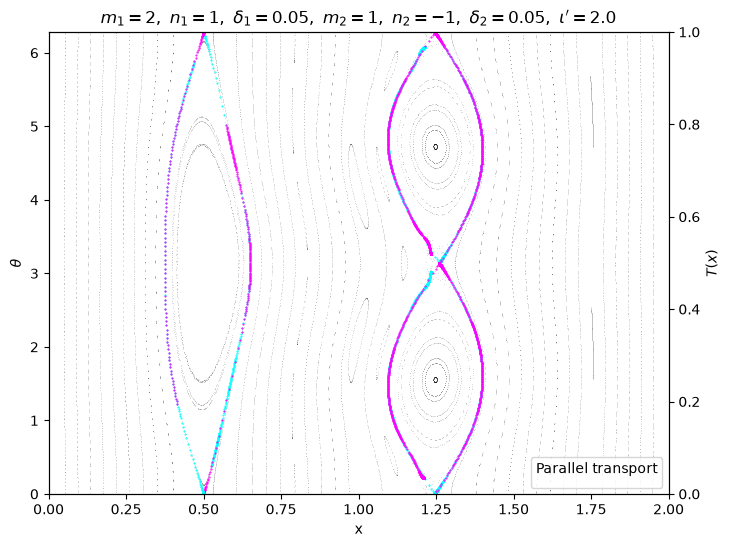

In [22]:
config_id = 21
fig, ax = plot_configuration(
    config_id,
    markersize=1,
    poincare=True,
    unwrapped=True,
    maxs=[500,530,500,500,None,None], maxu=[500,530,500,500,None,None],
    temperature=True,
    t_f=0.01,
    k_values=[4.0, 6.0, 8.0, 10.0, 12.0]
)
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

Temperature file not found: 2I_k4.0_tf0.01_d0.3_0.3_res201_m1_dT_iota2.0_Neumann.jld2
Temperature file not found: 2I_k6.0_tf0.01_d0.3_0.3_res201_m1_dT_iota2.0_Neumann.jld2
Temperature file not found: 2I_k8.0_tf0.01_d0.3_0.3_res201_m1_dT_iota2.0_Neumann.jld2
Temperature file not found: 2I_k10.0_tf0.01_d0.3_0.3_res201_m1_dT_iota2.0_Neumann.jld2
Temperature file not found: 2I_k12.0_tf0.01_d0.3_0.3_res201_m1_dT_iota2.0_Neumann.jld2


C:\Users\mirei\AppData\Local\Temp\ipykernel_21468\382293941.py:64: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_T.legend(


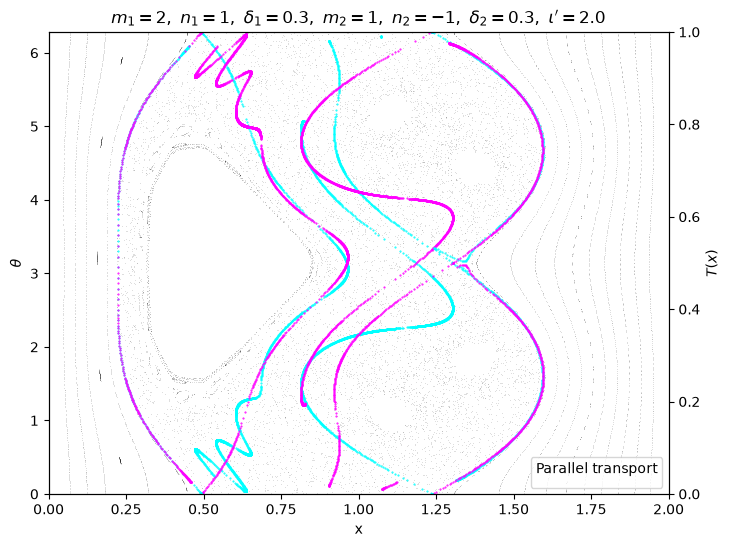

In [23]:
config_id = 22
fig, ax = plot_configuration(
    config_id,
    markersize=1,
    poincare=True,
    unwrapped=True,
    maxs=[400,1800,1000,350,None,None], maxu=[340,700,1400,500,2520,None],
    temperature=True,
    t_f=0.01,
    k_values=[4.0, 6.0, 8.0, 10.0, 12.0]
)
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

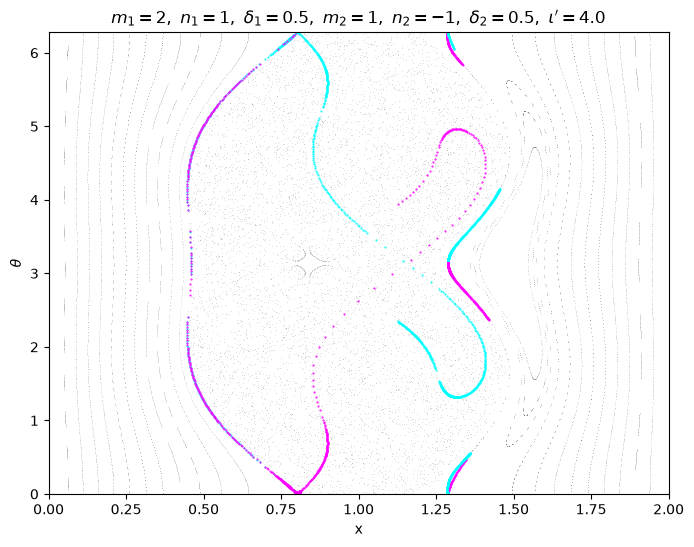

In [25]:
config_id = 23
fig, ax = plot_configuration(
    config_id,
    markersize=1,
    poincare=True,
    unwrapped=True,
    maxs=[None,None,None,None,400,570], maxu=[None,None,None,None,None,257],
    temperature=False,
    t_f=0.01,
    k_values=[4.0, 6.0, 8.0, 10.0, 12.0]
)
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

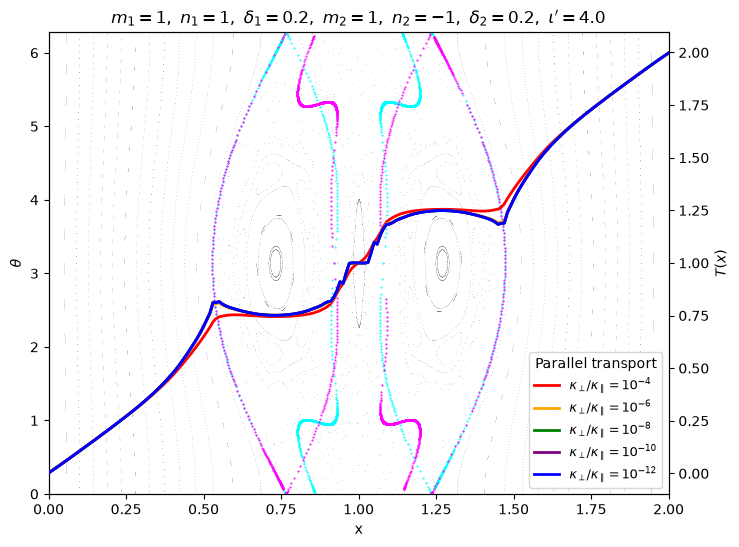

In [27]:
config_id = 113
fig, ax = plot_configuration(
    config_id,
    markersize=1,
    poincare=True,
    unwrapped=True,
    maxs=[1650,None,None,1650], maxu=[1650,None,None,1650],
    temperature=True,
    t_f=0.01,
    k_values=[4.0, 6.0, 8.0, 10.0, 12.0]
)
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

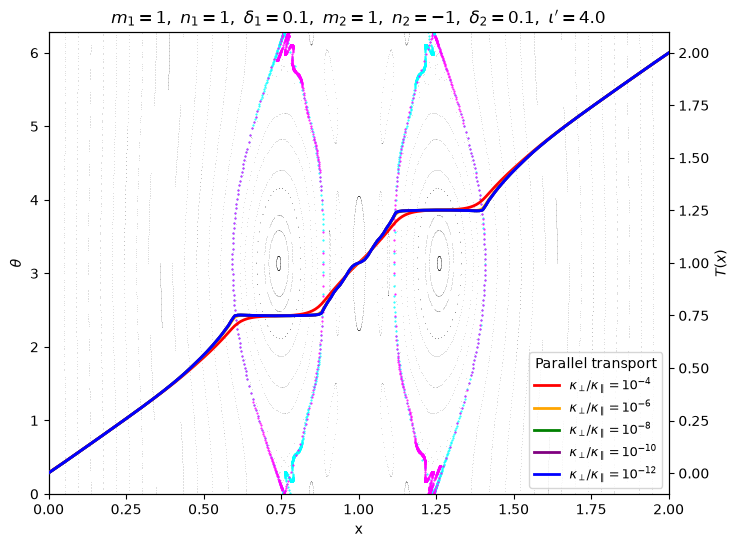

In [28]:
config_id = 114
fig, ax = plot_configuration(
    config_id,
    markersize=1,
    poincare=True,
    unwrapped=True,
    maxs=[2200,None,None,2200], maxu=[2200,None,None,2200],
    temperature=True,
    t_f=0.01,
    k_values=[4.0, 6.0, 8.0, 10.0, 12.0]
)
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

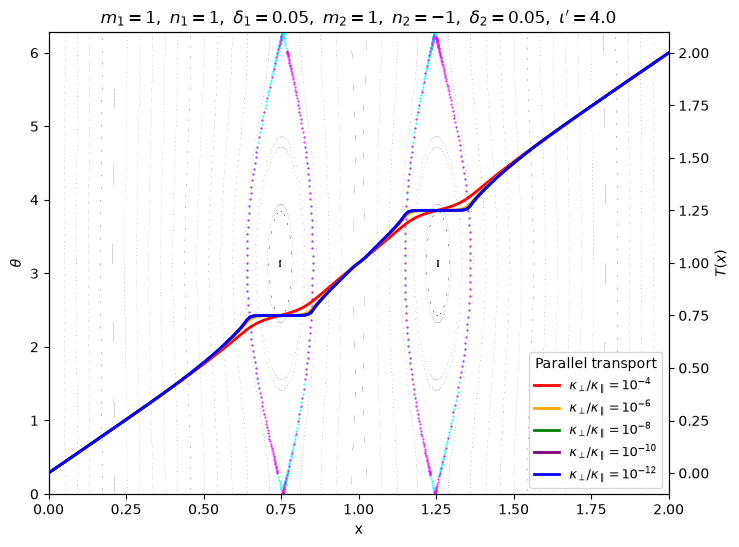

In [29]:
config_id = 115
fig, ax = plot_configuration(
    config_id,
    markersize=1,
    poincare=True,
    unwrapped=True,
    maxs=[None,None,None,None], maxu=[None,None,None,None],
    temperature=True,
    t_f=0.01,
    k_values=[4.0, 6.0, 8.0, 10.0, 12.0]
)
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

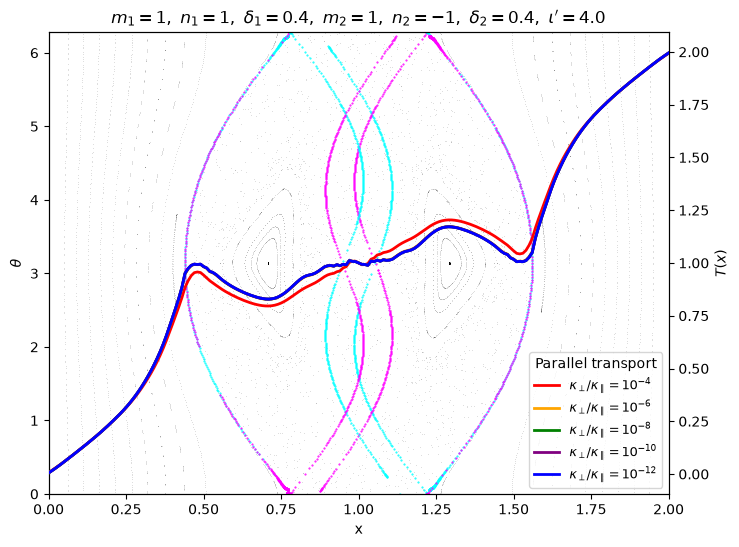

In [30]:
config_id = 116
fig, ax = plot_configuration(
    config_id,
    markersize=1,
    poincare=True,
    unwrapped=True,
    maxs=[330,500,500,330], maxu=[330,500,500,330],
    temperature=True,
    t_f=0.01,
    k_values=[4.0, 6.0, 8.0, 10.0, 12.0]
)
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

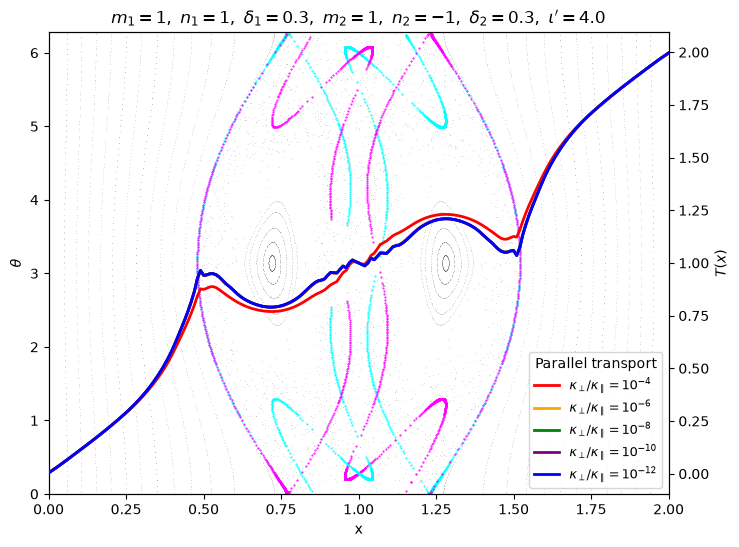

In [31]:
config_id = 117
fig, ax = plot_configuration(
    config_id,
    markersize=1,
    poincare=True,
    unwrapped=True,
    maxs=[1200,1000,1000,1700], maxu=[2076,1000,1000,1700],
    temperature=True,
    t_f=0.01,
    k_values=[4.0, 6.0, 8.0, 10.0, 12.0]
)
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

Temperature file not found: 2I_k4.0_tf0.01_d0.2_0.2_res201_m1_dT_iota3.0_Neumann.jld2
Temperature file not found: 2I_k6.0_tf0.01_d0.2_0.2_res201_m1_dT_iota3.0_Neumann.jld2
Temperature file not found: 2I_k8.0_tf0.01_d0.2_0.2_res201_m1_dT_iota3.0_Neumann.jld2
Temperature file not found: 2I_k10.0_tf0.01_d0.2_0.2_res201_m1_dT_iota3.0_Neumann.jld2
Temperature file not found: 2I_k12.0_tf0.01_d0.2_0.2_res201_m1_dT_iota3.0_Neumann.jld2


C:\Users\mirei\AppData\Local\Temp\ipykernel_21468\382293941.py:64: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_T.legend(


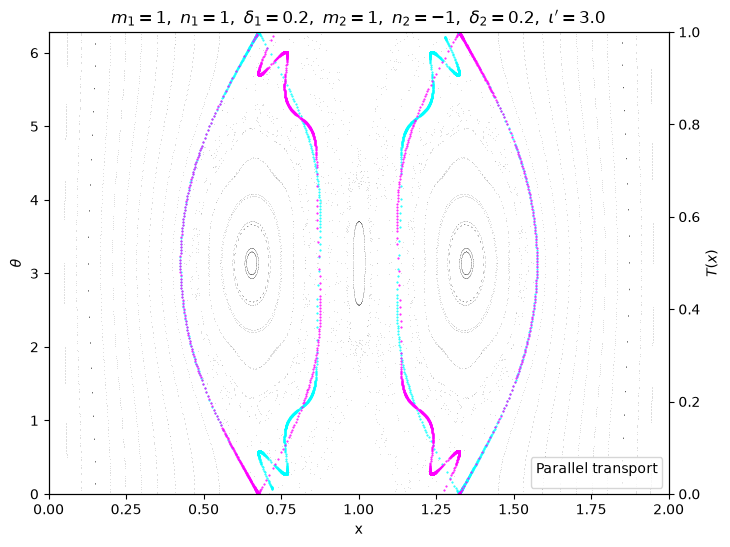

In [33]:
config_id = 118
fig, ax = plot_configuration(
    config_id,
    markersize=1,
    poincare=True,
    unwrapped=True,
    maxs=[1200,None,None,1200], maxu=[2132,None,None,2132],
    temperature=True,
    t_f=0.01,
    k_values=[4.0, 6.0, 8.0, 10.0, 12.0]
)
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

Temperature file not found: 2I_k4.0_tf0.01_d0.1_0.1_res201_m1_dT_iota3.0_Neumann.jld2
Temperature file not found: 2I_k6.0_tf0.01_d0.1_0.1_res201_m1_dT_iota3.0_Neumann.jld2
Temperature file not found: 2I_k8.0_tf0.01_d0.1_0.1_res201_m1_dT_iota3.0_Neumann.jld2
Temperature file not found: 2I_k10.0_tf0.01_d0.1_0.1_res201_m1_dT_iota3.0_Neumann.jld2
Temperature file not found: 2I_k12.0_tf0.01_d0.1_0.1_res201_m1_dT_iota3.0_Neumann.jld2


C:\Users\mirei\AppData\Local\Temp\ipykernel_21468\382293941.py:64: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_T.legend(


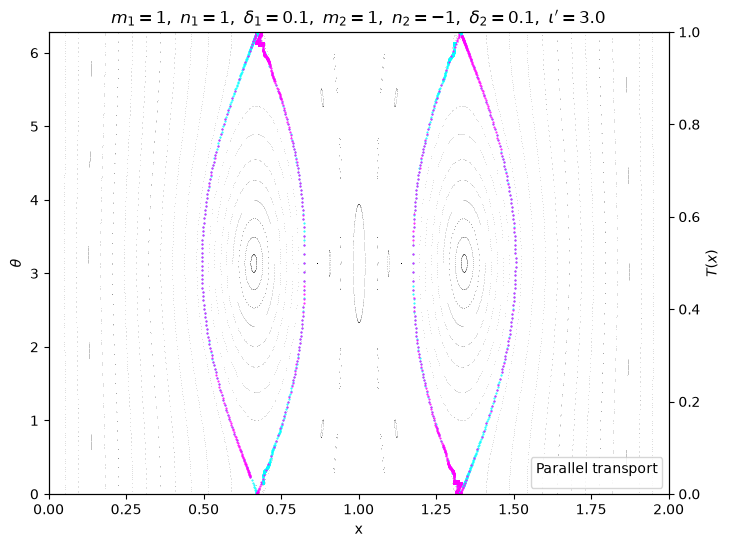

In [34]:
config_id = 119
fig, ax = plot_configuration(
    config_id,
    markersize=1,
    poincare=True,
    unwrapped=True,
    maxs=[1200,None,None,1200], maxu=[2132,None,None,2132],
    temperature=True,
    t_f=0.01,
    k_values=[4.0, 6.0, 8.0, 10.0, 12.0]
)
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

Temperature file not found: 2I_k4.0_tf0.01_d0.6_0.6_res201_m1_dT_iota3.0_Neumann.jld2
Temperature file not found: 2I_k6.0_tf0.01_d0.6_0.6_res201_m1_dT_iota3.0_Neumann.jld2
Temperature file not found: 2I_k8.0_tf0.01_d0.6_0.6_res201_m1_dT_iota3.0_Neumann.jld2
Temperature file not found: 2I_k10.0_tf0.01_d0.6_0.6_res201_m1_dT_iota3.0_Neumann.jld2
Temperature file not found: 2I_k12.0_tf0.01_d0.6_0.6_res201_m1_dT_iota3.0_Neumann.jld2


C:\Users\mirei\AppData\Local\Temp\ipykernel_21468\382293941.py:64: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_T.legend(


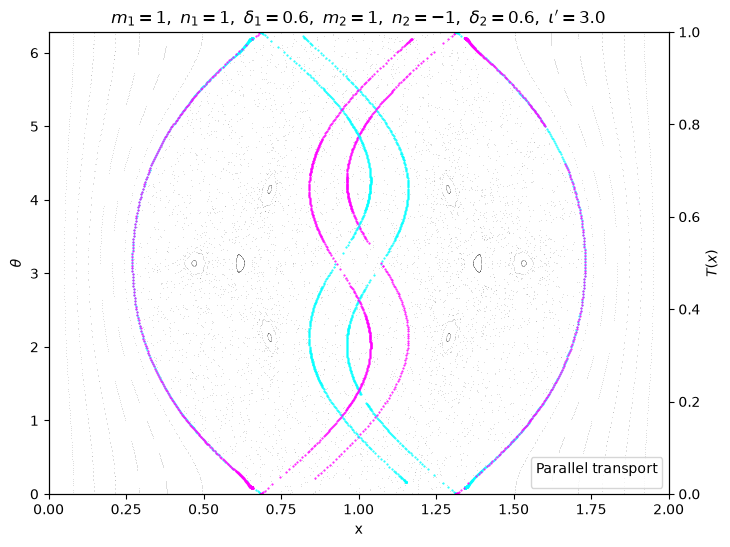

In [ ]:
config_id = 120
fig, ax = plot_configuration(
    config_id,
    markersize=1,
    poincare=True,
    unwrapped=True,
    maxs=[390,500,500,460], maxu=[330,500,500,450],
    temperature=True,
    t_f=0.01,
    k_values=[4.0, 6.0, 8.0, 10.0, 12.0]
)
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

Temperature file not found: 2I_k4.0_tf0.01_d0.7_0.7_res201_m1_dT_iota3.0_Neumann.jld2
Temperature file not found: 2I_k6.0_tf0.01_d0.7_0.7_res201_m1_dT_iota3.0_Neumann.jld2
Temperature file not found: 2I_k8.0_tf0.01_d0.7_0.7_res201_m1_dT_iota3.0_Neumann.jld2
Temperature file not found: 2I_k10.0_tf0.01_d0.7_0.7_res201_m1_dT_iota3.0_Neumann.jld2
Temperature file not found: 2I_k12.0_tf0.01_d0.7_0.7_res201_m1_dT_iota3.0_Neumann.jld2


C:\Users\mirei\AppData\Local\Temp\ipykernel_21468\382293941.py:64: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_T.legend(


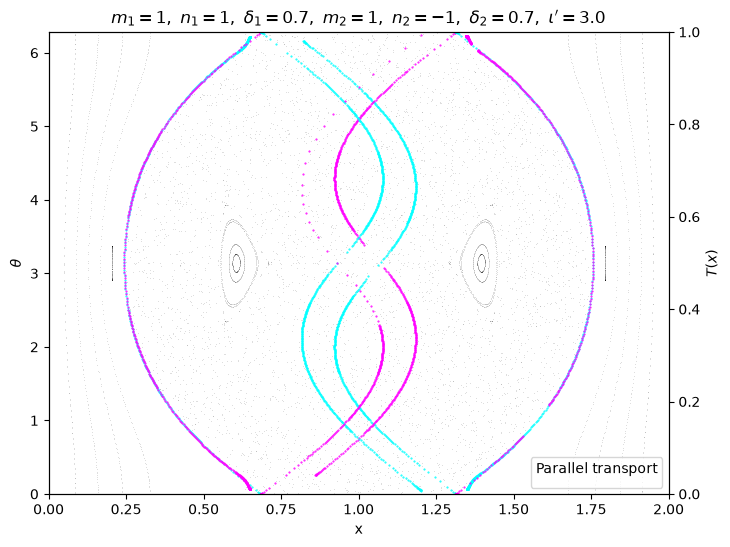

In [36]:
config_id = 121
fig, ax = plot_configuration(
    config_id,
    markersize=1,
    poincare=True,
    unwrapped=True,
    maxs=[540,500,500,540], maxu=[540,500,500,245],
    temperature=True,
    t_f=0.01,
    k_values=[4.0, 6.0, 8.0, 10.0, 12.0]
)
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")